In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

In [3]:
# importer les données
df = pd.read_csv('/content/sample_data/Car_Data (1).csv')
df.head()

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant


In [4]:
# Split des adresses
df[['Quartier', 'Ville']] = df['Adresse'].str.split(',', expand=True)

# Strip des adresses
df['Quartier'] = df['Quartier'].str.strip()
df['Ville'] = df['Ville'].str.strip()

# Supprimer l'ancienne colonne Adresse
df.drop('Adresse', axis=1, inplace=True)

# Afficher le résultat
df[['Quartier', 'Ville']].head()

,Quartier,Ville
0,Liberte 6,Dakar
1,Yoff,Dakar
2,Cité Damel,Dakar
3,Almadies,Dakar
4,Hlm,Dakar


In [5]:
# dimension des données
df.shape

(5507, 7)

In [6]:
df.head()

,Marque,Année,Boite_Vitesse,Prix,Venant_Occasion,Quartier,Ville
0,Mitsubishi,2017,Automatique,9750000,Venant,Liberte 6,Dakar
1,Ford,2009,Manuelle,2500000,D'occasion,Yoff,Dakar
2,BMW,2015,Automatique,15500000,D'occasion,Cité Damel,Dakar
3,Ford,2013,Automatique,3800000,D'occasion,Almadies,Dakar
4,GMC,2014,Automatique,7500000,Venant,Hlm,Dakar


In [7]:
# infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Marque           5507 non-null   object
 1   Année            5507 non-null   int64 
 2   Boite_Vitesse    5507 non-null   object
 3   Prix             5507 non-null   int64 
 4   Venant_Occasion  5507 non-null   object
 5   Quartier         5507 non-null   object
 6   Ville            5507 non-null   object
dtypes: int64(2), object(5)
memory usage: 301.3+ KB


In [8]:
# selection les variables catégorielles
cat_data = df.select_dtypes(exclude = 'number')
cat_data.head()

,Marque,Boite_Vitesse,Venant_Occasion,Quartier,Ville
0,Mitsubishi,Automatique,Venant,Liberte 6,Dakar
1,Ford,Manuelle,D'occasion,Yoff,Dakar
2,BMW,Automatique,D'occasion,Cité Damel,Dakar
3,Ford,Automatique,D'occasion,Almadies,Dakar
4,GMC,Automatique,Venant,Hlm,Dakar


In [9]:
# décrire les variables catégorielles
cat_data.describe().T

,count,unique,top,freq
Marque,5507,46,Ford,1391
Boite_Vitesse,5507,3,Automatique,4675
Venant_Occasion,5507,2,Venant,2855
Quartier,5507,86,Almadies,792
Ville,5507,1,Dakar,5507


In [10]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  val = df[col].value_counts()
  fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str), text_auto=True)
  fig.show()

In [11]:
# Diagrammes en barre des variables catégorielles
for col in cat_data.columns:
  countplot_func(col)

In [12]:
# selection des variables quantitatives
quant_data = df.select_dtypes(include = 'number')
quant_data.head()

,Année,Prix
0,2017,9750000
1,2009,2500000
2,2015,15500000
3,2013,3800000
4,2014,7500000


In [13]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Année,5507.0,2.014508e+03,3.089839e+00,1990.0,2013.0,2015.0,2016.0,2024.0
Prix,5507.0,1.110512e+07,1.619639e+07,1.0,4600000.0,7800000.0,12500000.0,779414131.0


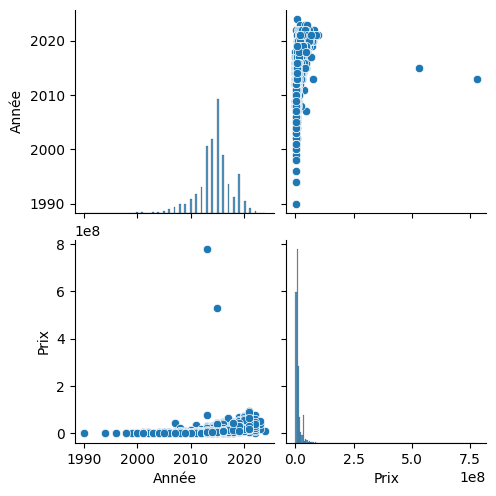

In [14]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

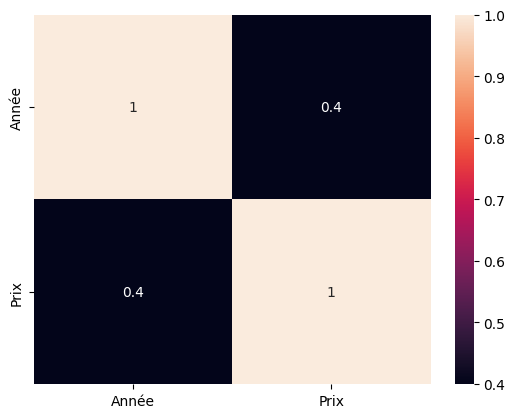

In [15]:
#matrice de correlation
sns.heatmap(quant_data.corr(), annot = True)
plt.show()

In [16]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

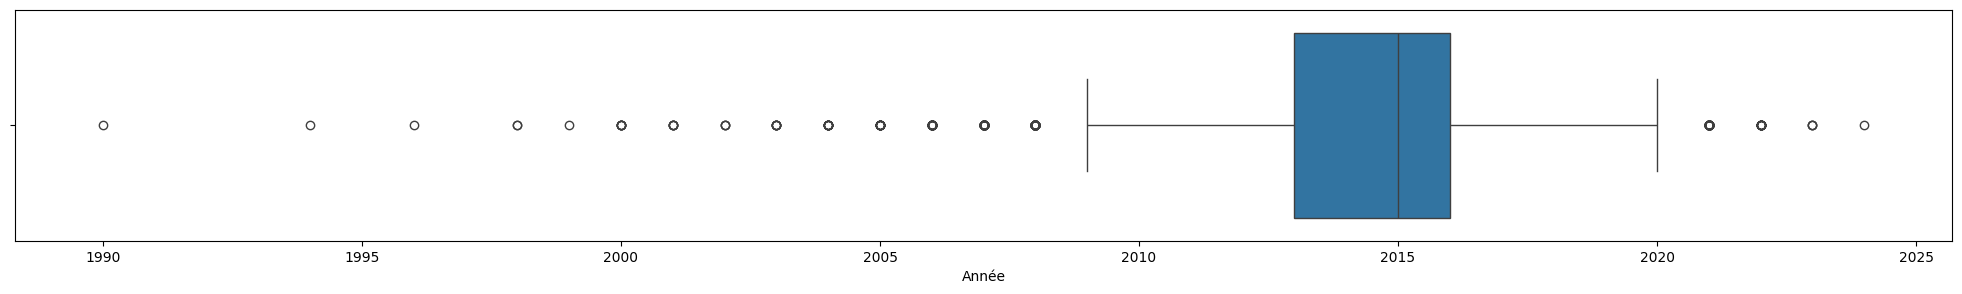

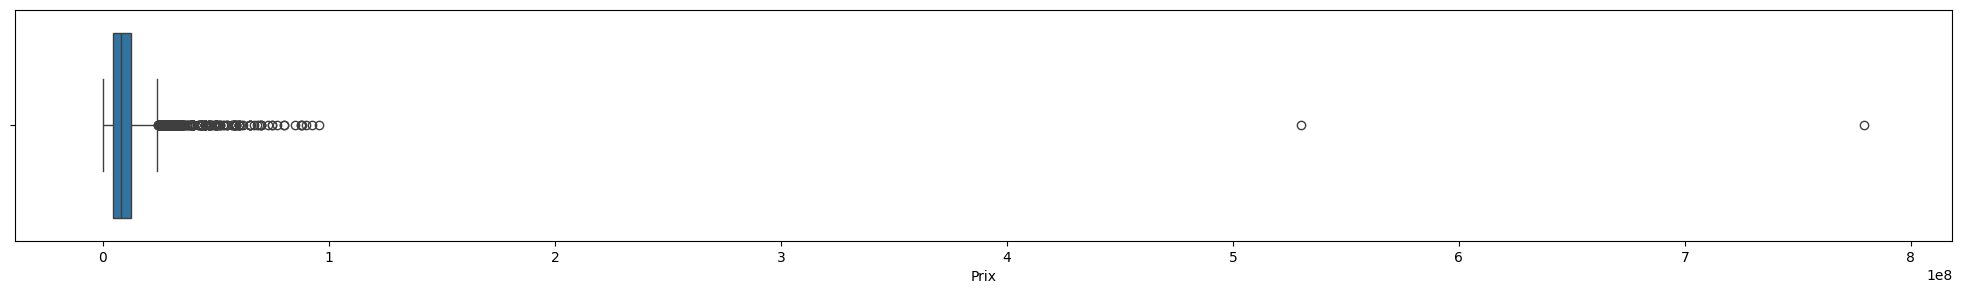

In [17]:
# boxplots des variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

In [22]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
import os
import joblib as jb

uniques = []
for col in cat_data.columns:
  uniques.append(np.unique(df[col]).tolist())
# Créer le dossier s'il n'existe pas
os.makedirs('/content/model', exist_ok=True)
# sauvegarde
jb.dump(uniques, '/content/model/uniques.joblib')

['/content/model/uniques.joblib']

In [53]:
import joblib as jb
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# Créer différents encodeurs pour les variables catégorielles
encoders = []
for i in range(len(cat_data.columns)):
  encoder = LabelEncoder()
  encoder.fit(df[cat_data.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  df[cat_data.columns[i]] = encoder.transform(df[cat_data.columns[i]]) # encoder les valeurs
  # rajouter l'encoder sur la liste encoders
  encoders.append(encoder)

df.head()

,Marque,Année,Boite_Vitesse,Prix,Venant_Occasion,Quartier,Ville
0,30,2017.0,0,9750000.0,1,49,0
1,13,2009.0,1,2500000.0,0,83,0
2,3,2015.0,0,15500000.0,0,11,0
3,13,2013.0,0,3800000.0,0,0,0
4,14,2014.0,0,7500000.0,1,38,0


In [54]:

# sauvegarde les encodeurs
jb.dump(encoders, '/content/model/encoders.joblib')

['/content/model/encoders.joblib']

In [24]:
from sklearn.impute import KNNImputer
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1 # interquantile
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [55]:
# imputation des valeurs extrêmes
for col in quant_data.columns:
  impute_func(df,col)

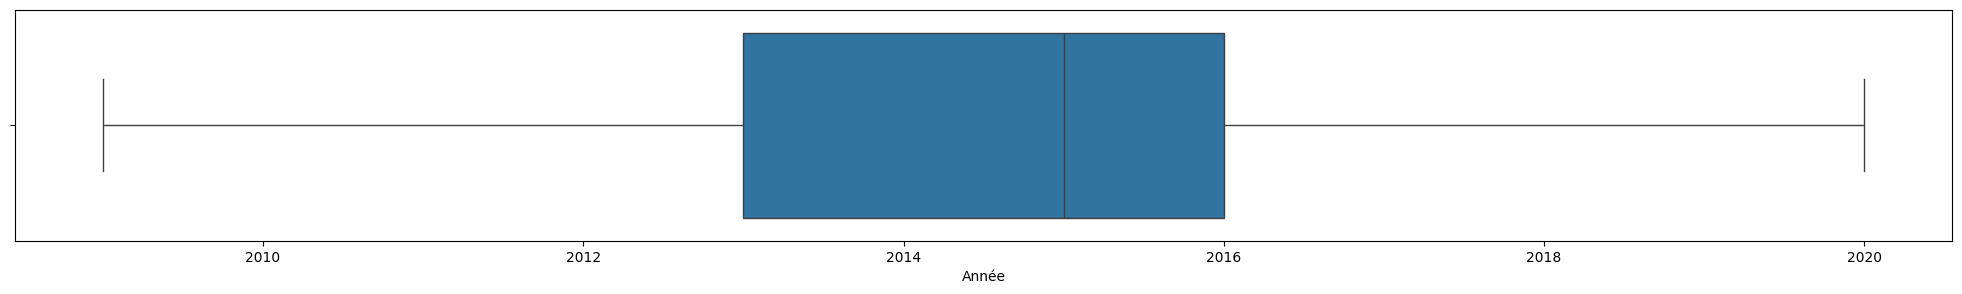

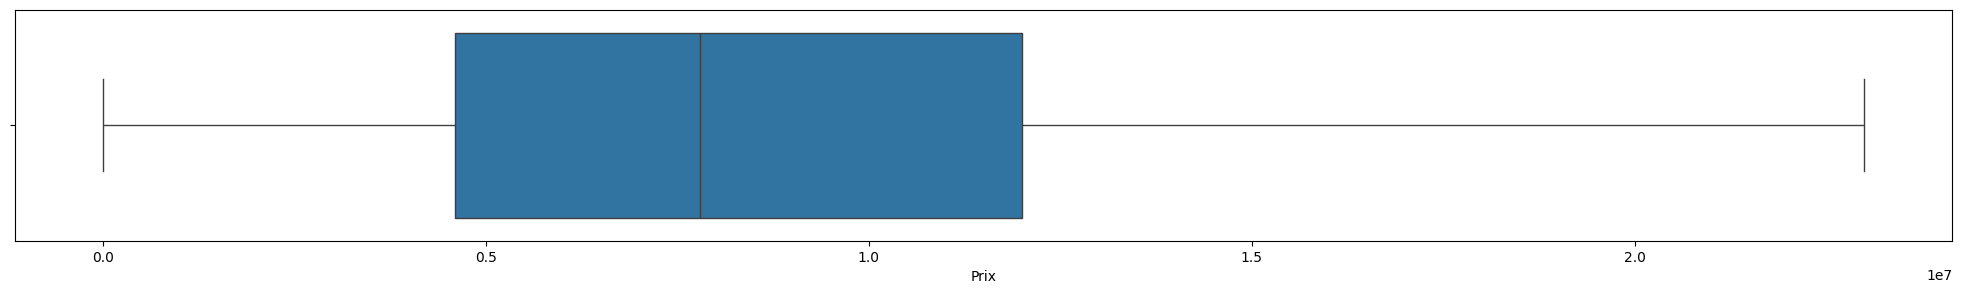

In [56]:
# Réafficher les boxplots
for col in quant_data.columns:
  boxplot_func(col)

In [57]:
# Fractionner les données en variables prédicteurs (x) et variable cibel(y)
x = df.drop('Venant_Occasion', axis = 1).values
y = df.Venant_Occasion.values
x[:5], y[:5]

(array([[3.000e+01, 2.017e+03, 0.000e+00, 9.750e+06, 4.900e+01, 0.000e+00],
        [1.300e+01, 2.009e+03, 1.000e+00, 2.500e+06, 8.300e+01, 0.000e+00],
        [3.000e+00, 2.015e+03, 0.000e+00, 1.550e+07, 1.100e+01, 0.000e+00],
        [1.300e+01, 2.013e+03, 0.000e+00, 3.800e+06, 0.000e+00, 0.000e+00],
        [1.400e+01, 2.014e+03, 0.000e+00, 7.500e+06, 3.800e+01, 0.000e+00]]),
 array([1, 0, 0, 0, 1]))

In [58]:
# normaliser les données
from sklearn.preprocessing import MinMaxScaler # Z = (X-Xmin)/(Xmax - Xmin)
scaler = MinMaxScaler()
x = scaler.fit_transform(x)
x[:5]

array([[0.66666667, 0.72727273, 0.        , 0.42391302, 0.57647059,
        0.        ],
       [0.28888889, 0.        , 0.5       , 0.10869561, 0.97647059,
        0.        ],
       [0.06666667, 0.54545455, 0.        , 0.67391303, 0.12941176,
        0.        ],
       [0.28888889, 0.36363636, 0.        , 0.16521736, 0.        ,
        0.        ],
       [0.31111111, 0.45454545, 0.        , 0.32608693, 0.44705882,
        0.        ]])

In [59]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
#train : données d'entrainement, val: données utiliser pour évaluer chaque et test: données pour tester le modèle le plus performant
from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y, train_size = 0.8, random_state = 42)# 80% -- 20%
x_val, x_test, y_val, y_test = train_test_split(x_val_test, y_val_test, train_size = 0.5, random_state = 42)# 80% -- 20%

### <font color = 'teal'>Logistic Regression<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [30]:
from sklearn.model_selection import GridSearchCV, KFold
# Recherche des paramètres optimaux pour la logistic regression
from sklearn.linear_model import LogisticRegression
#validation croisé et figé
cv=KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params={"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}
# instantier le modèle Logistic regression
lg=LogisticRegression()
# instantier le modèle gridsearch
grid=GridSearchCV(lg,params,cv=cv)
# lancer la recherche
grid.fit(x_train,y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LogisticRegression(),
             param_grid={'C': array([1.00000000e-03, 4.64158883e-03, 2.15443469e-02, 1.00000000e-01,
       4.64158883e-01, 2.15443469e+00, 1.00000000e+01, 4.64158883e+01,
       2.15443469e+02, 1.00000000e+03]),
                         'penalty': ['l1', 'l2']})

In [31]:
# Afficher les paramètres optimaux
grid.best_params_


{'C': np.float64(0.021544346900318832), 'penalty': 'l2'}

In [32]:
# Entrainer la logistic regression en utilisant les paramètres optimaux
lg_model = LogisticRegression(C=0.46415888336127775, penalty='l2')
lg_model.fit(x_train, y_train)

LogisticRegression(C=0.46415888336127775)

###### <font color ='bisque'>Evaluation du modèle

In [33]:
# fonction d'évaluation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='micro')
  return acc, f1

In [34]:
# Accuracy et F1 score du modèle sur les données de validation
acc_lg, f1_lg = evaluation(lg_model)
print(f"accuracy: {acc_lg} ---F1 score : {f1_lg}")

accuracy: 0.7912885662431942 ---F1 score : 0.7912885662431942


In [35]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):

    y_pred = model_objet.predict(x_val)
    # Confusion matrix
    cnf_matr = confusion_matrix(y_val, y_pred, labels=[0,1,2,3])

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=['Occasion','Neuf', 'Reconditionné','Venant'])
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figure

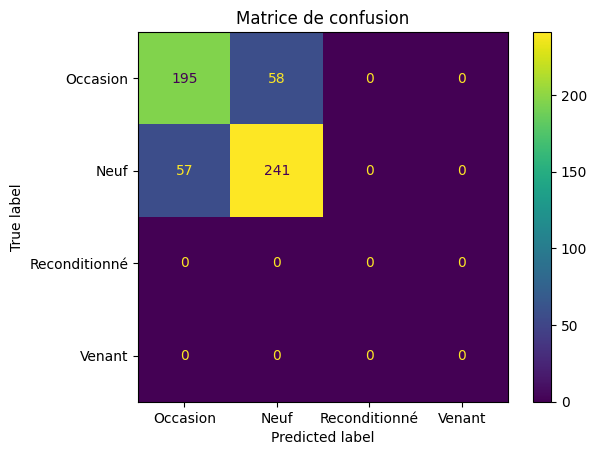

In [36]:
# Matrice de confusion
CM_visualisation(lg_model)

Decision Tree

Recherche des paramètre optimaux

In [37]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier()
# instantier le modèle gridsearch
grid__ = GridSearchCV(dt, param__, cv = cv)
# entrainer le modèle
grid__.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': array([ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])})

In [38]:
# afficher les paramètres optimaux
grid__.best_params_

{'criterion': 'entropy', 'max_depth': np.int64(4)}

###### <font color = 'bisque'> Entrainement du modèle

In [39]:
# Entrainer le modèle en utilisant les paramètres optimaux
dt_model = DecisionTreeClassifier(criterion = 'gini', max_depth = 13)
dt_model.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=13)

###### <font color ='bisque'>Evaluation du modèle<font>

In [40]:
# Accuracy et F1 score du modèle sur les données de validation
acc_dt, f1_dt = evaluation(dt_model)
print(f"Accuracy : {acc_dt} --- F1 score : {f1_dt}")

Accuracy : 0.7404718693284936 --- F1 score : 0.7404718693284936


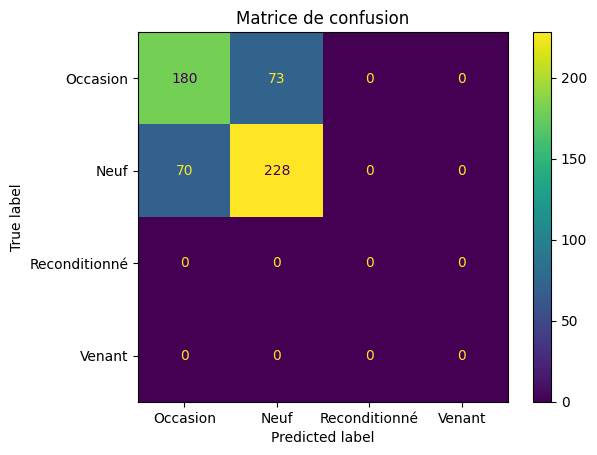

In [41]:
# Matrice de confusion
CM_visualisation(dt_model)

### <font color = 'teal'>Random Forest<font>

In [42]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params = param_grid = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
# instantier le modèle Random F(orest
rf = RandomForestClassifier()
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=rf, param_grid=params, cv= cv)
# entrainer le modèle
grid.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [np.int64(3), np.int64(4), np.int64(5),
                                       np.int64(6), np.int64(7), np.int64(8),
                                       np.int64(9), np.int64(10), np.int64(11),
                                       np.int64(12), np.int64(13),
                                       np.int64(14)],
                         'n_estimators': [np.int64(10), np.int64(20),
                                          np.int64(30), np.int64(40),
                                          np.int64(50), np.int64(60),
                                          np.int64(70), np.int64(80),
                                          np.int64(90)]})

In [43]:
# Afficher les paramètres optimaux
grid.best_params_

{'criterion': 'gini', 'max_depth': np.int64(8), 'n_estimators': np.int64(70)}

In [44]:
# Entrainer Random Forest en utilisant les paramètres optimaux
rf_model = RandomForestClassifier(criterion= 'gini', max_depth=9,  n_estimators = 30)
rf_model.fit(x_train, y_train)

RandomForestClassifier(max_depth=9, n_estimators=30)

##### <font color ='bisque'>Evaluation du Random Forest<font>

In [45]:
# Accuracy et F1 score du modèle sur les données de validation
acc_rf, f1_rf = evaluation(rf_model)
print(f"accuracy: {acc_rf} ---F1 score : {f1_rf}")

accuracy: 0.7985480943738656 ---F1 score : 0.7985480943738656


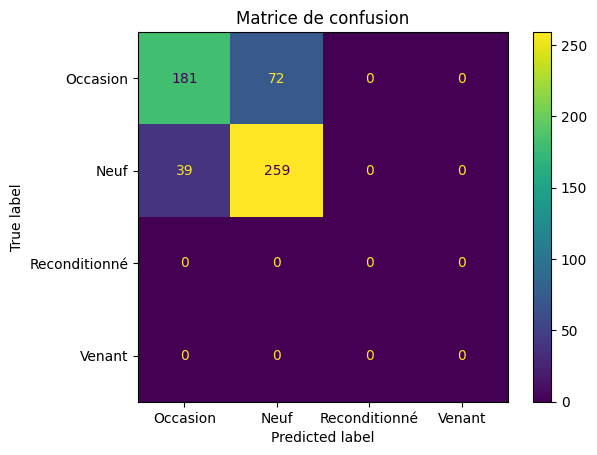

In [46]:
# Matrice de confusion
CM_visualisation(rf_model)

In [47]:
#Diagramme des performances
list_names = ['LG', 'DT', 'RF']
list_acc = [acc_lg, acc_dt, acc_rf]
list_f1 = [f1_lg, f1_dt,f1_rf]
list_final = [list_acc, list_f1]
for i in range(2):
  fig = px.bar(y=list_names, x= list_final[i], color = list_names, text_auto = True)
  fig.show()

In [61]:
# télécharger le modèle le plus performant
jb.dump(rf_model, '/content/model/rf_model.joblib')

['/content/model/rf_model.joblib']

### <font color ='bisque'>Tester le modèle le plus performant<font>

In [49]:
#Echantillons
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# prédictions
y_pred_10 = rf_model.predict(x_test_10)
classnames = ['occasion', 'neuf', 'reconditionné', 'venant']
for i in range(10):
  print(f"Prédiction {str(i +1)} : {classnames[y_pred_10[i]]}  -- {classnames[y_test_10[i]]}")

Prédiction 1 : occasion  -- occasion
Prédiction 2 : neuf  -- neuf
Prédiction 3 : occasion  -- occasion
Prédiction 4 : neuf  -- neuf
Prédiction 5 : occasion  -- neuf
Prédiction 6 : occasion  -- occasion
Prédiction 7 : neuf  -- neuf
Prédiction 8 : neuf  -- occasion
Prédiction 9 : occasion  -- neuf
Prédiction 10 : occasion  -- occasion
